<a href="https://colab.research.google.com/github/franciscamandas/PRAKTIKUM-ADW/blob/main/TUGAS_KELOMPOK_MINGGU_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumlah observasi per simulasi: 100
Jumlah replikasi: 30
Seed: 2513

Lima baris pertama hasil estimasi:


,Replikasi,Model,Metode,Parameter,Estimasi
0,1,"ARIMA(1,0,2)",OLS,ar.L1,0.522530
1,1,"ARIMA(1,0,2)",OLS,ma.L1,-0.361945
2,1,"ARIMA(1,0,2)",OLS,ma.L2,0.414774
3,1,"ARIMA(1,0,2)",ML,ar.L1,0.513058
4,1,"ARIMA(1,0,2)",ML,ma.L1,-0.370579



Tabel ringkasan bias dan varians:


,Model,Parameter,Metode,Parameter Sebenarnya,Jumlah Estimasi Valid,Rata-rata Estimasi,Bias,Varians
0,"ARIMA(1,0,2)",ar.L1,OLS,0.55,30,0.5512,0.0012,0.0849
1,"ARIMA(1,0,2)",ar.L1,ML,0.55,30,0.5480,-0.0020,0.0855
2,"ARIMA(1,0,2)",ma.L1,OLS,-0.35,30,-0.3626,-0.0126,0.0903
3,"ARIMA(1,0,2)",ma.L1,ML,-0.35,30,-0.3633,-0.0133,0.0902
4,"ARIMA(1,0,2)",ma.L2,OLS,0.20,30,0.2386,0.0386,0.0176
5,"ARIMA(1,0,2)",ma.L2,ML,0.20,30,0.2384,0.0384,0.0181
6,"ARIMA(2,1,2)",ar.L1,OLS,0.35,30,0.2926,-0.0574,0.1427
7,"ARIMA(2,1,2)",ar.L1,ML,0.35,30,0.2893,-0.0607,0.2215
8,"ARIMA(2,1,2)",ar.L2,OLS,0.20,30,0.1480,-0.0520,0.1341
9,"ARIMA(2,1,2)",ar.L2,ML,0.20,30,0.1027,-0.0973,0.1864


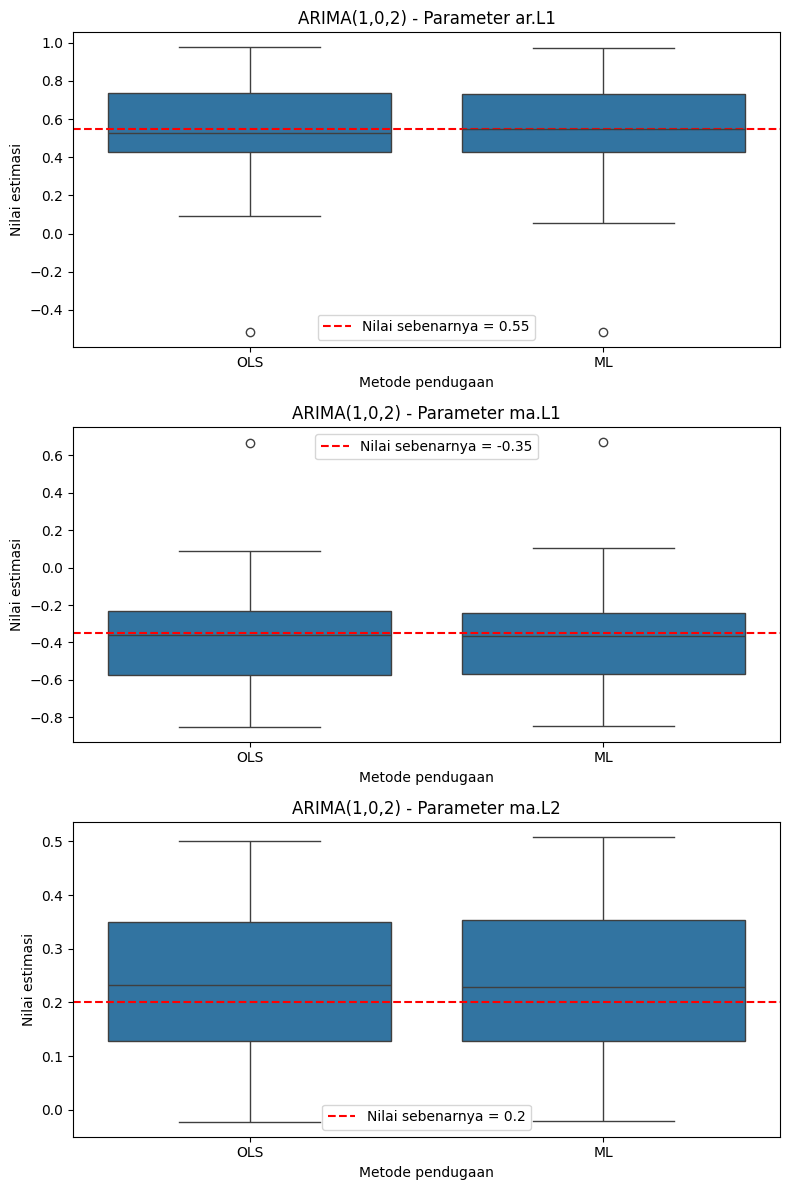

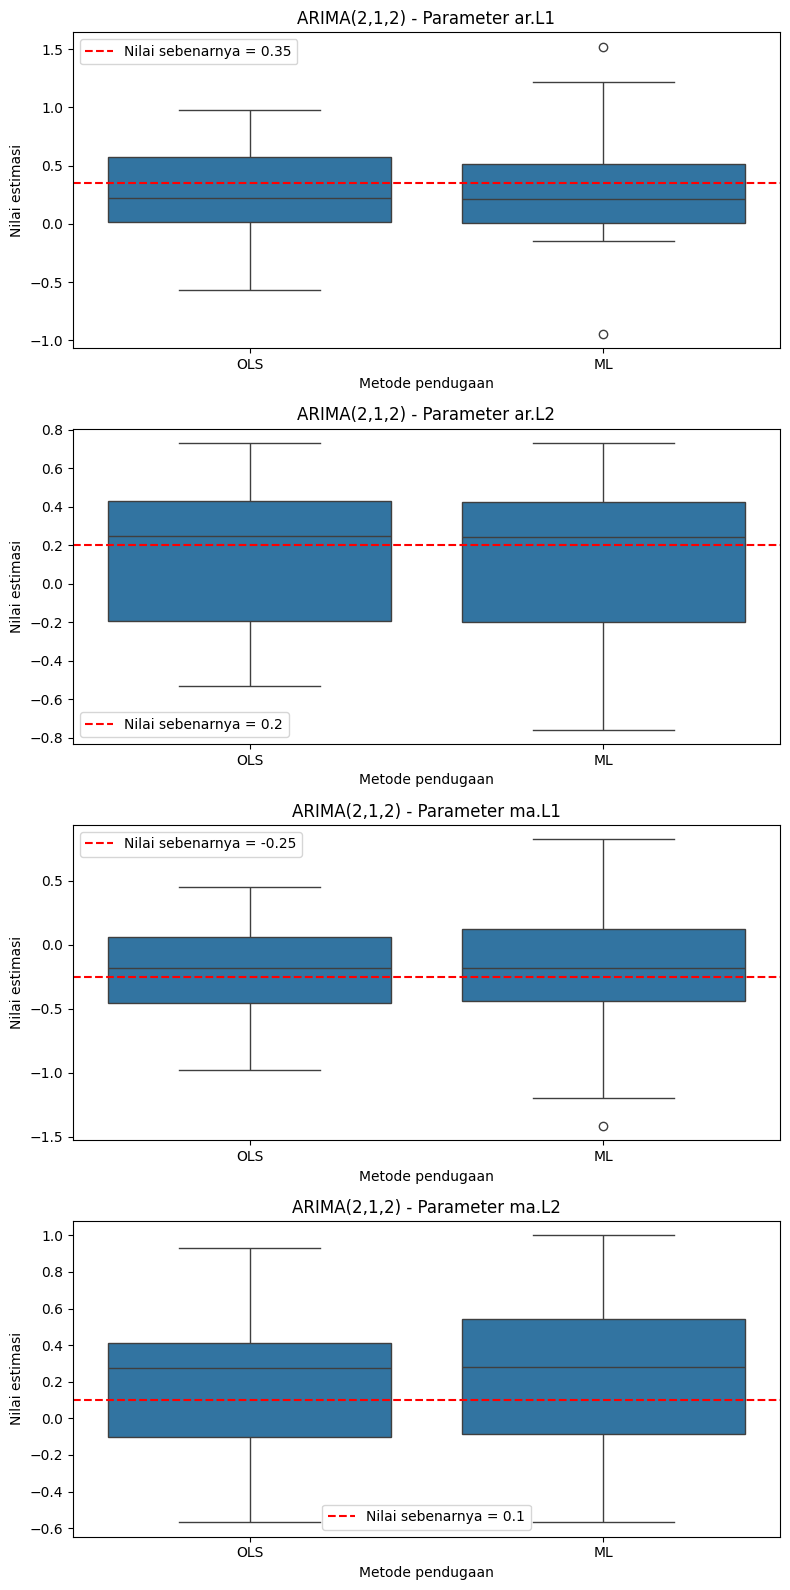


Interpretasi angka untuk ARIMA(1,0,2):
- ar.L1: bias absolut lebih kecil pada OLS; varians lebih kecil pada OLS.
- ma.L1: bias absolut lebih kecil pada OLS; varians lebih kecil pada ML.
- ma.L2: bias absolut lebih kecil pada ML; varians lebih kecil pada OLS.

Interpretasi angka untuk ARIMA(2,1,2):
- ar.L1: bias absolut lebih kecil pada OLS; varians lebih kecil pada OLS.
- ar.L2: bias absolut lebih kecil pada OLS; varians lebih kecil pada OLS.
- ma.L1: bias absolut lebih kecil pada ML; varians lebih kecil pada OLS.
- ma.L2: bias absolut lebih kecil pada OLS; varians lebih kecil pada OLS.


In [ ]:
# ============================================================
# TUGAS PENDUGAAN PARAMETER MODEL ARIMA
# Kelompok 8
# Model: ARIMA(1,0,2) dan ARIMA(2,1,2)
# Metode: OLS dan Maximum Likelihood (ML)
# Seed: 2513 | Data: 100 | Replikasi: 30
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from scipy.optimize import minimize
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# A. PENGATURAN
# ------------------------------------------------------------

SEED = 2513
N = 100
B = 30

PARAMETER_BENAR = {
    "ARIMA(1,0,2)": {
        "ar.L1": 0.55,
        "ma.L1": -0.35,
        "ma.L2": 0.20
    },
    "ARIMA(2,1,2)": {
        "ar.L1": 0.35,
        "ar.L2": 0.20,
        "ma.L1": -0.25,
        "ma.L2": 0.10
    }
}

PARAMETER_EVALUASI = {
    model: [
        p for p in parameter.keys()
        if p.startswith("ar.") or p.startswith("ma.")
    ]
    for model, parameter in PARAMETER_BENAR.items()
}

# ------------------------------------------------------------
# B. FUNGSI SIMULASI DATA
# ------------------------------------------------------------

def simulasi_102(n, rng):
    """Simulasi ARIMA(1,0,2), yaitu proses ARMA(1,2)."""

    model = ArmaProcess(
        ar=np.array([1, -0.55]),
        ma=np.array([1, -0.35, 0.20])
    )

    return model.generate_sample(
        nsample=n,
        distrvs=rng.standard_normal
    )


def simulasi_212(n, rng):
    """
    Simulasi ARIMA(2,1,2).
    Data hasil differencing mengikuti ARMA(2,2),
    kemudian diintegrasikan kembali.
    """

    model = ArmaProcess(
        ar=np.array([1, -0.35, -0.20]),
        ma=np.array([1, -0.25, 0.10])
    )

    data_diff = model.generate_sample(
        nsample=n - 1,
        distrvs=rng.standard_normal
    )

    data = np.concatenate([
        [100.0],
        100.0 + np.cumsum(data_diff)
    ])

    return data


# ------------------------------------------------------------
# C. PENDUGAAN PARAMETER DENGAN OLS
# ------------------------------------------------------------

def estimasi_ols(data, p, d, q):
    """
    Pendugaan OLS dengan meminimumkan jumlah kuadrat
    residual secara kondisional.

    Catatan: ini merupakan implementasi OLS sederhana
    dengan residual awal ditetapkan nol.
    """

    x = np.diff(data, n=d) if d > 0 else np.asarray(data)
    x = np.asarray(x, dtype=float)

    nama_parameter = (
        [f"ar.L{i}" for i in range(1, p + 1)]
        + [f"ma.L{i}" for i in range(1, q + 1)]
    )

    lag_awal = max(p, q)

    def hitung_residual(parameter):
        phi = parameter[:p]
        theta = parameter[p:]

        residual = np.zeros(len(x))

        for t in range(len(x)):
            bagian_ar = sum(
                phi[i] * x[t - i - 1]
                for i in range(p)
                if t - i - 1 >= 0
            )

            bagian_ma = sum(
                theta[j] * residual[t - j - 1]
                for j in range(q)
                if t - j - 1 >= 0
            )

            residual[t] = x[t] - bagian_ar - bagian_ma

        return residual

    def fungsi_objektif(parameter):
        residual = hitung_residual(parameter)
        return np.sum(residual[lag_awal:] ** 2)

    nilai_awal = [
        np.zeros(p + q),
        np.array([0.3] * p + [-0.2] * q),
        np.array([0.5] * p + [-0.3] * q),
        np.array([-0.2] * p + [0.2] * q)
    ]

    hasil_optimasi = []

    for awal in nilai_awal:
        hasil = minimize(
            fungsi_objektif,
            awal,
            method="L-BFGS-B",
            bounds=[(-0.98, 0.98)] * (p + q)
        )

        if hasil.success and np.isfinite(hasil.fun):
            hasil_optimasi.append(hasil)

    if not hasil_optimasi:
        return {
            nama: np.nan
            for nama in nama_parameter
        }

    terbaik = min(hasil_optimasi, key=lambda hasil: hasil.fun)

    estimasi = dict(zip(nama_parameter, terbaik.x))

    return estimasi


# ------------------------------------------------------------
# D. PENDUGAAN PARAMETER DENGAN MAXIMUM LIKELIHOOD
# ------------------------------------------------------------

def estimasi_ml(data, order, nama_model):
    """Pendugaan parameter ARIMA menggunakan Maximum Likelihood."""

    try:
        hasil = ARIMA(
            data,
            order=order,
            trend="n",
            enforce_stationarity=True,
            enforce_invertibility=True
        ).fit()

        parameter_hasil = dict(
            zip(hasil.model.param_names, hasil.params)
        )

        return {
            nama: parameter_hasil.get(nama, np.nan)
            for nama in PARAMETER_EVALUASI[nama_model]
        }

    except Exception:
        return {
            nama: np.nan
            for nama in PARAMETER_EVALUASI[nama_model]
        }


# ------------------------------------------------------------
# E. SIMULASI 30 REPLIKASI DAN PENDUGAAN PARAMETER
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)
hasil_simulasi = []

for replikasi in range(1, B + 1):

    data_102 = simulasi_102(N, rng)
    data_212 = simulasi_212(N, rng)

    daftar_model = [
        ("ARIMA(1,0,2)", data_102, (1, 0, 2), 1, 0, 2),
        ("ARIMA(2,1,2)", data_212, (2, 1, 2), 2, 1, 2)
    ]

    for nama_model, data, order, p, d, q in daftar_model:

        hasil_ols = estimasi_ols(data, p, d, q)
        hasil_ml = estimasi_ml(data, order, nama_model)

        for metode, estimasi in [
            ("OLS", hasil_ols),
            ("ML", hasil_ml)
        ]:

            for parameter in PARAMETER_EVALUASI[nama_model]:
                hasil_simulasi.append({
                    "Replikasi": replikasi,
                    "Model": nama_model,
                    "Metode": metode,
                    "Parameter": parameter,
                    "Estimasi": estimasi.get(parameter, np.nan)
                })


df_hasil = pd.DataFrame(hasil_simulasi)

print("Jumlah observasi per simulasi:", N)
print("Jumlah replikasi:", B)
print("Seed:", SEED)

print("\nLima baris pertama hasil estimasi:")
display(df_hasil.head())


# ------------------------------------------------------------
# F. MENGHITUNG RATA-RATA, BIAS, DAN VARIANS
# ------------------------------------------------------------

ringkasan = []

for nama_model, parameter_list in PARAMETER_EVALUASI.items():

    for parameter in parameter_list:
        nilai_benar = PARAMETER_BENAR[nama_model][parameter]

        for metode in ["OLS", "ML"]:

            subset = df_hasil.loc[
                (df_hasil["Model"] == nama_model)
                & (df_hasil["Parameter"] == parameter)
                & (df_hasil["Metode"] == metode),
                "Estimasi"
            ].dropna()

            rata_rata = subset.mean()
            bias = rata_rata - nilai_benar
            varians = subset.var(ddof=1)

            ringkasan.append({
                "Model": nama_model,
                "Parameter": parameter,
                "Metode": metode,
                "Parameter Sebenarnya": nilai_benar,
                "Jumlah Estimasi Valid": len(subset),
                "Rata-rata Estimasi": rata_rata,
                "Bias": bias,
                "Varians": varians
            })

df_ringkasan = pd.DataFrame(ringkasan)

print("\nTabel ringkasan bias dan varians:")
display(df_ringkasan.round(4))


# ------------------------------------------------------------
# G. BOXPLOT ESTIMASI SELURUH PARAMETER AR DAN MA
# ------------------------------------------------------------

for nama_model, parameter_list in PARAMETER_EVALUASI.items():

    fig, axes = plt.subplots(
        nrows=len(parameter_list),
        ncols=1,
        figsize=(8, 4 * len(parameter_list))
    )

    if len(parameter_list) == 1:
        axes = [axes]

    for ax, parameter in zip(axes, parameter_list):

        subset = df_hasil[
            (df_hasil["Model"] == nama_model)
            & (df_hasil["Parameter"] == parameter)
        ].copy()

        sns.boxplot(
            data=subset,
            x="Metode",
            y="Estimasi",
            ax=ax
        )

        nilai_benar = PARAMETER_BENAR[nama_model][parameter]

        ax.axhline(
            nilai_benar,
            color="red",
            linestyle="--",
            label=f"Nilai sebenarnya = {nilai_benar}"
        )

        ax.set_title(f"{nama_model} - Parameter {parameter}")
        ax.set_xlabel("Metode pendugaan")
        ax.set_ylabel("Nilai estimasi")
        ax.legend()

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# H. PERBANDINGAN BIAS DAN VARIANS OLS DAN ML
# ------------------------------------------------------------

for nama_model, parameter_list in PARAMETER_EVALUASI.items():

    print(f"\nInterpretasi angka untuk {nama_model}:")

    tabel = df_ringkasan[
        df_ringkasan["Model"] == nama_model
    ]

    for parameter in parameter_list:

        bagian = tabel[tabel["Parameter"] == parameter]

        ols = bagian[bagian["Metode"] == "OLS"].iloc[0]
        ml = bagian[bagian["Metode"] == "ML"].iloc[0]

        if abs(ols["Bias"]) < abs(ml["Bias"]):
            metode_bias = "OLS"
        elif abs(ml["Bias"]) < abs(ols["Bias"]):
            metode_bias = "ML"
        else:
            metode_bias = "OLS dan ML sama"

        if ols["Varians"] < ml["Varians"]:
            metode_var = "OLS"
        elif ml["Varians"] < ols["Varians"]:
            metode_var = "ML"
        else:
            metode_var = "OLS dan ML sama"

        print(
            f"- {parameter}: bias absolut lebih kecil pada {metode_bias}; "
            f"varians lebih kecil pada {metode_var}."
        )


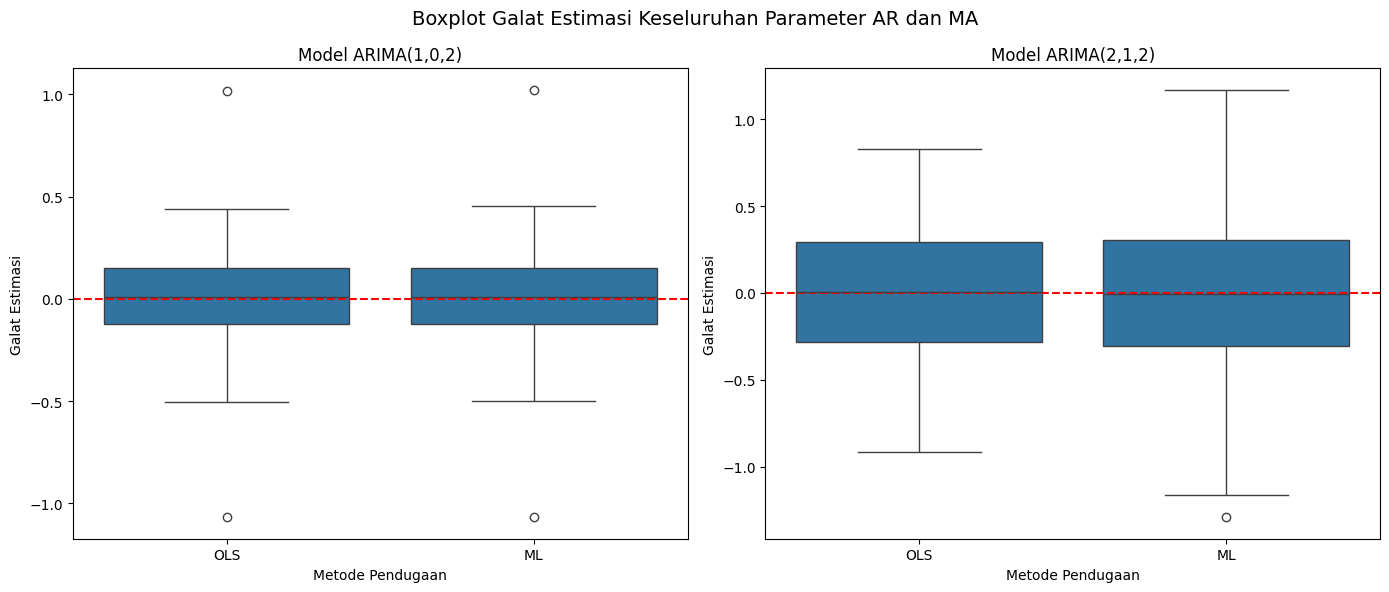

In [ ]:

# ============================================================
# I. BOXPLOT KESELURUHAN MODEL
# Perbandingan OLS dan ML berdasarkan 30 replikasi
# ============================================================

df_boxplot = df_hasil[
    df_hasil["Parameter"].str.startswith(("ar.", "ma."))
].copy()

df_boxplot["Parameter Sebenarnya"] = df_boxplot.apply(
    lambda baris: PARAMETER_BENAR[
        baris["Model"]
    ][baris["Parameter"]],
    axis=1
)

df_boxplot["Galat Estimasi"] = (
    df_boxplot["Estimasi"]
    - df_boxplot["Parameter Sebenarnya"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

urutan_model = [
    "ARIMA(1,0,2)",
    "ARIMA(2,1,2)"
]

for ax, nama_model in zip(axes, urutan_model):

    data_model = df_boxplot[
        df_boxplot["Model"] == nama_model
    ].copy()

    sns.boxplot(
        data=data_model,
        x="Metode",
        y="Galat Estimasi",
        ax=ax
    )

    ax.axhline(
        y=0,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Galat nol"
    )

    ax.set_title(f"Model {nama_model}")
    ax.set_xlabel("Metode Pendugaan")
    ax.set_ylabel("Galat Estimasi")

    # Hilangkan kotak legenda
    if ax.get_legend() is not None:
        ax.get_legend().remove()

plt.suptitle(
    "Boxplot Galat Estimasi Keseluruhan Parameter AR dan MA",
    fontsize=14
)

plt.tight_layout()
plt.show()


**Interpretasi:**

Interpretasi Boxplot Galat Estimasi Parameter AR dan MA
Berdasarkan boxplot galat estimasi parameter AR dan MA, terlihat bahwa metode OLS dan Maximum Likelihood (ML) menghasilkan distribusi galat yang relatif serupa pada model ARIMA(1,0,2). Median galat pada kedua metode berada di sekitar nol, dengan rentang interkuartil yang hampir sama. Hal ini menunjukkan bahwa sebaran galat estimasi kedua metode relatif sebanding pada model tersebut. Meskipun demikian, terdapat beberapa pencilan pada kedua metode yang menunjukkan adanya hasil estimasi dengan galat relatif besar dibandingkan sebagian besar hasil lainnya.

Pada model ARIMA(2,1,2), distribusi galat estimasi juga memiliki median yang berada di sekitar nol. Namun, rentang sebaran galat terlihat lebih lebar dibandingkan model ARIMA(1,0,2), terutama pada metode ML. Rentang whisker metode ML mencapai nilai yang lebih ekstrem, baik pada sisi positif maupun negatif, dan terdapat pencilan pada sisi negatif. Kondisi ini menunjukkan bahwa hasil estimasi pada model ARIMA(2,1,2) memiliki variasi galat yang lebih besar, khususnya pada metode ML.

Secara keseluruhan, boxplot menunjukkan bahwa distribusi galat estimasi pada model ARIMA(1,0,2) cenderung lebih terkonsentrasi dibandingkan ARIMA(2,1,2). Sementara itu, pada masing-masing model, distribusi galat metode OLS dan ML tampak relatif serupa, meskipun metode ML pada ARIMA(2,1,2) memperlihatkan rentang galat yang lebih lebar. Temuan ini mengindikasikan bahwa karakteristik model dan metode pendugaan dapat berkaitan dengan variasi galat estimasi yang dihasilkan.
